In [33]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from ultralytics.utils.plotting import Annotator
import os
import sys

# Pfade zur Logik (mapping.py liegt einen Ordner höher in /scripts)
sys.path.append(os.path.abspath('..'))
from src.mapping import SHIP_MAPPING, CAT_COLORS

print("Setup abgeschlossen. Bibliotheken und Mapping geladen.")


Setup abgeschlossen. Bibliotheken und Mapping geladen.


In [34]:
model_path = '../models/final_weights/v2_3classes_best.pt'
model = YOLO(model_path)
print(f"V2-Modell geladen: {model_path}")

V2-Modell geladen: ../models/final_weights/v2_3classes_best.pt


In [35]:
def analyze_and_plot_image(image_path, model, conf=0.6):
    img = cv2.imread(image_path)
    if img is None:
        print(f"Fehler: Bild '{image_path}' konnte nicht geladen werden.")
        return
    
    results = model.predict(source=image_path, conf=conf, iou=0.4, verbose=False)

    annotator = Annotator(img.copy(), line_width=1)

    stats = {cat: 0 for cat in SHIP_MAPPING.keys()}
    stats['Unknown'] = 0

    for r in results:
        for box in r.boxes:
            cls_id = int(box.cls[0])
            label = model.names[cls_id]
            conf_val = float(box.conf[0])
            coords = box.xyxy[0]

            category = "Unknown"
            label_str = str(label).lower()
            
            for cat, classes in SHIP_MAPPING.items():
                # Erkennt Hauptkategorie ODER alten Untertyp
                if label_str == cat.lower() or \
                   (label_str == "civilian" and cat == "Civilian/Other") or \
                   label in classes:
                    category = cat
                    break

            stats[category] += 1
            color = CAT_COLORS.get(category, (128, 128, 128))
            annotator.box_label(coords, f"{category} {conf_val:.2f}", color=color, txt_color=(255, 255, 255))

    return annotator.result(), stats



Analysiere Szenario: Militärische Überwachung: San Diego Base
Änderungen in der Schiffspräsenz:
 Alarm: 6x Military hinzugekommen.


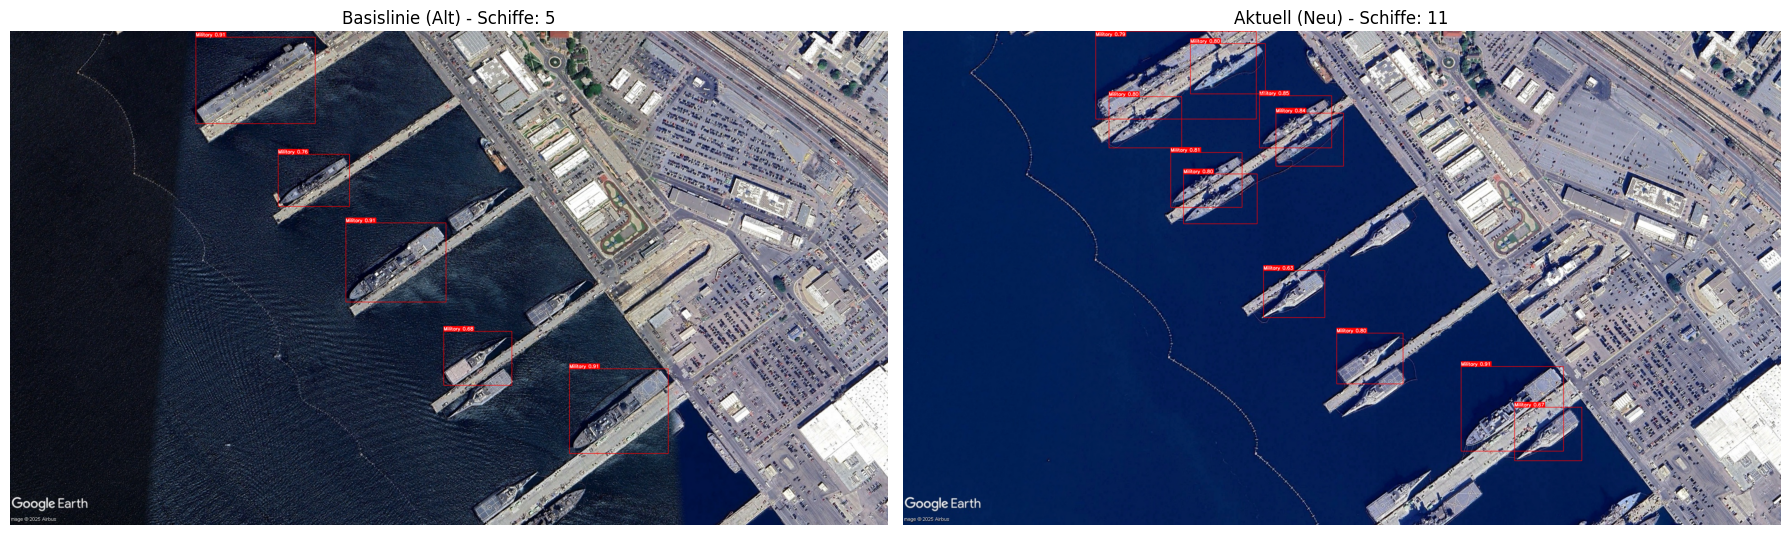


Analysiere Szenario: Logistik-Tracking: Hafen Hamburg
Änderungen in der Schiffspräsenz:
 Alarm: 1x Military hinzugekommen.
 Alarm: 2x Logistics hinzugekommen.
 Alarm: 1x Civilian/Other hinzugekommen.


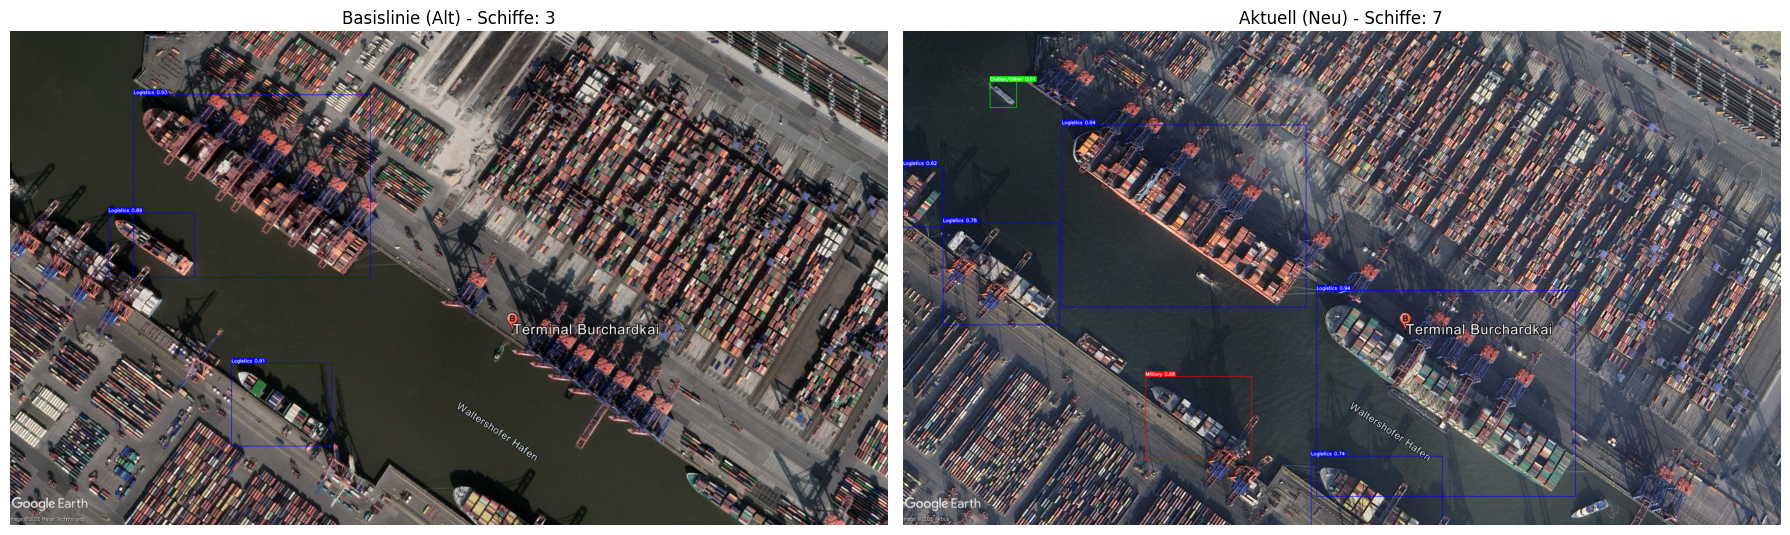

In [36]:
scenarios = {
    "military_san_diego": {
        "titel": "Militärische Überwachung: San Diego Base",
        "alt": '../data/processed/ship_data/test/images/military_old.jpg',
        "neu": '../data/processed/ship_data/test/images/military_new.jpg'
    },
    "logistic_hamburg": {
        "titel": "Logistik-Tracking: Hafen Hamburg",
        "alt": '../data/processed/ship_data/test/images/logistics_old.jpg',
        "neu": '../data/processed/ship_data/test/images/logistics_new.jpg'
    }
}

for key, scenario in scenarios.items():
    print(f"\nAnalysiere Szenario: {scenario['titel']}")

    #Analyse der beiden Zeitpunkte
    res_old, stats_old = analyze_and_plot_image(scenario['alt'], model)
    res_new, stats_new = analyze_and_plot_image(scenario['neu'], model)

    #Protokollierung der Änderungen
    print("Änderungen in der Schiffspräsenz:")
    found_changes = False
    for cat in SHIP_MAPPING.keys():
        diff = stats_new[cat] - stats_old[cat]
        if diff > 0:
            print(f" Alarm: {diff}x {cat} hinzugekommen.")
            found_changes = True
        elif diff < 0:
            print(f" Alarm: {-diff}x {cat} verschwunden.")
            found_changes = True
    if not found_changes:
        print(" Keine signifikanten Änderungen festgestellt.")
    
    #Visualisierung der Ergebnisse
    fig, axs = plt.subplots(1, 2, figsize=(18, 8))
    axs[0].imshow(cv2.cvtColor(res_old, cv2.COLOR_BGR2RGB))
    axs[0].set_title(f"Basislinie (Alt) - Schiffe: {sum(stats_old.values())}")
    axs[0].axis('off')

    axs[1].imshow(cv2.cvtColor(res_new, cv2.COLOR_BGR2RGB))
    axs[1].set_title(f"Aktuell (Neu) - Schiffe: {sum(stats_new.values())}")
    axs[1].axis('off')

    plt.tight_layout()
    plt.show()